## **Result after doing reanalysis** ##

 understanding credit behavior using advanced analytics. Our goal is to predict customer risk, improve payment cycles, and guide business credit decisions."



 ## **Credit Management** ##

Late payments are rising across sectors

Difficult to segment customers by risk

Traditional credit scores lack behavioral depth

No clear strategy to identify prepaid or ghost customers

Speaker Notes:
"Most businesses still rely on basic aging reports. But in reality, customer behavior is complex and dynamic — we need deeper insights."

## **What We Did** ##

Used real sales and receipt data from 2018–2024

Cleaned & normalized customer identifiers

Calculated behavioral metrics for over 5000 customers

Built a credit scoring system from scratch

Speaker Notes:
"We built our own behavioral score — not from third-party credit agencies — but using internal data, ensuring it's highly relevant."

## **Advanced Metrics** ##

Early Payment Score

% Receipts Delayed > 90 Days

Advance Payment Ratio

Estimated Credit Limit

Credit Utilization Ratio

Delay Penalty & Credit Penalty

Credit Score (100–900)

Risk Category (High, Medium, Low)

Inactivity Ratio

First/Last Transaction

Clusters (via ML)

Speaker Notes:
"Each metric gives us a different angle — are they paying early? Are they using too much credit? Are they inactive?"

## **Insights:** ##

22% of customers pay within 30 days = ideal payers

11% have chronic delays > 90 days

17% over-utilize credit beyond 90%

9% have had no activity in last 6 months

ML clustering helped identify 4 customer behavior types


"These metrics help us separate reliable customers from risky ones and allow customized actions."



## **Business Value** ##

Improve cash flow by rewarding early payers

Reduce exposure to high-risk clients

Monitor dormant or ghost accounts

Justify credit limit changes with real data

Build automated alerts based on score drops

## **Future** ##

Add predictive modeling for future payment behavior

Send proactive alerts to sales team

Build auto-approval systems for trusted customers

In [327]:
import pandas as pd
import numpy as np
from datetime import datetime
import os
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.preprocessing import MinMaxScaler
from xgboost import XGBClassifier
from xgboost import XGBRegressor, XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from imblearn.over_sampling import RandomOverSampler
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from keras.models import Model
from keras.layers import Input, Dense
import seaborn as sns
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor
import joblib
from keras.models import load_model
from keras.losses import MeanSquaredError




In [91]:
sales_df= pd.read_csv(r"D:\Insightrix Project\Nova Agri Project\combined datawork\sales.csv", encoding='ISO-8859-1')
receipts_df= pd.read_csv(r"D:\Insightrix Project\Nova Agri Project\combined datawork\Receipts_2018_to_2024_corrected.csv", encoding='ISO-8859-1')

C:\Users\gzar9\AppData\Local\Temp\ipykernel_1588\3135144987.py:1: DtypeWarning: Columns (6) have mixed types. Specify dtype option on import or set low_memory=False.
  sales_df= pd.read_csv(r"D:\Insightrix Project\Nova Agri Project\combined datawork\sales.csv", encoding='ISO-8859-1')


In [92]:
sales_df.head()

,Date,Normalized,Particulars,GSTIN/UIN,Location,Rate,Value,Debit,Gross Total
0,02-Apr-18,"Sri Anantha Agro Agencies, Bhadrachalam","Sri Anantha Agro Agencies, Bhadrachalam",36ABJPY8288J1ZK,KOTHAGUDEM -(BHADRACHALAM),373.45/pac,9336.25,11016.77 Dr,11016.77
1,02-Apr-18,ANNAPURNA FERTLIZERS PESTICIDES & SEEDS-GANDHI...,ANNAPURNA FERTLIZERS PESTICIDES & SEEDS-GANDHI...,36BACPA1422R1ZU,ETURNAGARAM,1346.22/pac,40386.5,47656.08 Dr,47656.08
2,02-Apr-18,Sri Vinayaka Fertilisers-Utrumilli,Sri Vinayaka Fertilisers-Utrumilli,37AFOPN1588F1Z0,RAVULAPALEM,373.45/pac,18672.5,22033.55 Dr,22033.55
3,02-Apr-18,SRI SAI AGRO AGENCIES- METPALLY,SRI SAI AGRO AGENCIES- METPALLY,36ALQPD1069H1Z1,KARIMNAGAR (KARIMNAGAR),438.90/pac,26334.0,31074.12 Dr,31074.12
4,02-Apr-18,Sri Venkateswara Seeds & Pesticides-Bikhnoor,Sri Venkateswara Seeds & Pesticides-Bikhnoor,36ANSPG7354E1ZQ,MEDAK,582.63/lts,6991.6,7830.60 Dr,7830.60


In [93]:
sales_df.rename(columns={"Column1": "Normalized"}, inplace=True)

In [94]:
receipts_df.head()

,Date,Normalized,Particulars,Credit
0,04-01-2018,SRI VENKATESHWARA FERT AND PEST-CHINNABOINAPALLY,SRI VENKATESHWARA FERT AND PEST-CHINNABOINAPALLY,10000.0
1,04-01-2018,GAYATRI FERTILIZERS & PESTICIDES-MOMINPET,GAYATRI FERTILIZERS & PESTICIDES-MOMINPET,6500.0
2,04-01-2018,Maruthi Traders-Parkal,Maruthi Traders-Parkal,10000.0
3,04-01-2018,SRI VENKATESHWARA AGRIMALL -RAMAYAMPET,SRI VENKATESHWARA AGRIMALL -RAMAYAMPET,300000.0
4,04-02-2018,New Vinay Agencies-Khammam,New Vinay Agencies-Khammam,10000.0


In [95]:
sales_df.isnull().sum()

Date               0
Normalized         0
Particulars        0
GSTIN/UIN          0
Location           0
Rate           15235
Value              0
Debit              0
Gross Total        0
dtype: int64

In [96]:
receipts_df.isnull().sum()

Date           0
Normalized     0
Particulars    0
Credit         0
dtype: int64

In [97]:
sales_df.shape

(80377, 9)

In [98]:
receipts_df.shape

(57452, 4)

## Function to parse date format

Standardizing the Dataset

In [99]:
import re

sales_df["Normalized"] = sales_df["Normalized"].str.lower().str.replace(",", "").str.replace(" ", "").str.replace("-", "").str.replace("_", "").apply(lambda x: re.sub(r'[^\w]', '', x))

In [100]:
sales_df.head()

,Date,Normalized,Particulars,GSTIN/UIN,Location,Rate,Value,Debit,Gross Total
0,02-Apr-18,sriananthaagroagenciesbhadrachalam,"Sri Anantha Agro Agencies, Bhadrachalam",36ABJPY8288J1ZK,KOTHAGUDEM -(BHADRACHALAM),373.45/pac,9336.25,11016.77 Dr,11016.77
1,02-Apr-18,annapurnafertlizerspesticidesseedsgandhinagar,ANNAPURNA FERTLIZERS PESTICIDES & SEEDS-GANDHI...,36BACPA1422R1ZU,ETURNAGARAM,1346.22/pac,40386.5,47656.08 Dr,47656.08
2,02-Apr-18,srivinayakafertilisersutrumilli,Sri Vinayaka Fertilisers-Utrumilli,37AFOPN1588F1Z0,RAVULAPALEM,373.45/pac,18672.5,22033.55 Dr,22033.55
3,02-Apr-18,srisaiagroagenciesmetpally,SRI SAI AGRO AGENCIES- METPALLY,36ALQPD1069H1Z1,KARIMNAGAR (KARIMNAGAR),438.90/pac,26334.0,31074.12 Dr,31074.12
4,02-Apr-18,srivenkateswaraseedspesticidesbikhnoor,Sri Venkateswara Seeds & Pesticides-Bikhnoor,36ANSPG7354E1ZQ,MEDAK,582.63/lts,6991.6,7830.60 Dr,7830.60


In [101]:
receipts_df["Normalized"] = receipts_df["Normalized"].str.lower().str.replace(",", "").str.replace(" ", "").str.replace("-", "").str.replace("_", "").apply(lambda x: re.sub(r'[^\w]', '', x))

In [102]:
receipts_df.head()

,Date,Normalized,Particulars,Credit
0,04-01-2018,srivenkateshwarafertandpestchinnaboinapally,SRI VENKATESHWARA FERT AND PEST-CHINNABOINAPALLY,10000.0
1,04-01-2018,gayatrifertilizerspesticidesmominpet,GAYATRI FERTILIZERS & PESTICIDES-MOMINPET,6500.0
2,04-01-2018,maruthitradersparkal,Maruthi Traders-Parkal,10000.0
3,04-01-2018,srivenkateshwaraagrimallramayampet,SRI VENKATESHWARA AGRIMALL -RAMAYAMPET,300000.0
4,04-02-2018,newvinayagencieskhammam,New Vinay Agencies-Khammam,10000.0


In [103]:
# Combine all normalized values from both datasets
all_particulars = pd.concat([
    sales_df[["Normalized"]],
    receipts_df[["Normalized"]]
]).drop_duplicates().reset_index(drop=True)

# Assign unique particular_id
all_particulars["particular_id"] = range(1, len(all_particulars) + 1)

# Merge particular_id back into both datasets
sales_df = sales_df.merge(all_particulars, on="Normalized", how="left")
receipts_df = receipts_df.merge(all_particulars, on="Normalized", how="left")


In [104]:
sales_df.head()

,Date,Normalized,Particulars,GSTIN/UIN,Location,Rate,Value,Debit,Gross Total,particular_id
0,02-Apr-18,sriananthaagroagenciesbhadrachalam,"Sri Anantha Agro Agencies, Bhadrachalam",36ABJPY8288J1ZK,KOTHAGUDEM -(BHADRACHALAM),373.45/pac,9336.25,11016.77 Dr,11016.77,1
1,02-Apr-18,annapurnafertlizerspesticidesseedsgandhinagar,ANNAPURNA FERTLIZERS PESTICIDES & SEEDS-GANDHI...,36BACPA1422R1ZU,ETURNAGARAM,1346.22/pac,40386.5,47656.08 Dr,47656.08,2
2,02-Apr-18,srivinayakafertilisersutrumilli,Sri Vinayaka Fertilisers-Utrumilli,37AFOPN1588F1Z0,RAVULAPALEM,373.45/pac,18672.5,22033.55 Dr,22033.55,3
3,02-Apr-18,srisaiagroagenciesmetpally,SRI SAI AGRO AGENCIES- METPALLY,36ALQPD1069H1Z1,KARIMNAGAR (KARIMNAGAR),438.90/pac,26334.0,31074.12 Dr,31074.12,4
4,02-Apr-18,srivenkateswaraseedspesticidesbikhnoor,Sri Venkateswara Seeds & Pesticides-Bikhnoor,36ANSPG7354E1ZQ,MEDAK,582.63/lts,6991.6,7830.60 Dr,7830.60,5


In [105]:
receipts_df.head()

,Date,Normalized,Particulars,Credit,particular_id
0,04-01-2018,srivenkateshwarafertandpestchinnaboinapally,SRI VENKATESHWARA FERT AND PEST-CHINNABOINAPALLY,10000.0,29
1,04-01-2018,gayatrifertilizerspesticidesmominpet,GAYATRI FERTILIZERS & PESTICIDES-MOMINPET,6500.0,297
2,04-01-2018,maruthitradersparkal,Maruthi Traders-Parkal,10000.0,1190
3,04-01-2018,srivenkateshwaraagrimallramayampet,SRI VENKATESHWARA AGRIMALL -RAMAYAMPET,300000.0,70
4,04-02-2018,newvinayagencieskhammam,New Vinay Agencies-Khammam,10000.0,362


In [106]:
sales_df.sort_values(by="particular_id", inplace=True)
sales_df.head()

,Date,Normalized,Particulars,GSTIN/UIN,Location,Rate,Value,Debit,Gross Total,particular_id
0,02-Apr-18,sriananthaagroagenciesbhadrachalam,"Sri Anantha Agro Agencies, Bhadrachalam",36ABJPY8288J1ZK,KOTHAGUDEM -(BHADRACHALAM),373.45/pac,9336.25,11016.77 Dr,11016.77,1
13217,11-Dec-18,sriananthaagroagenciesbhadrachalam,"Sri Anantha Agro Agencies, Bhadrachalam",36ABJPY8288J1ZK,KOTHAGUDEM -(BHADRACHALAM),739.75/Nos,14795.0,15534.76 Dr,15534.76,1
28901,20-Nov-19,sriananthaagroagenciesbhadrachalam,"Sri Anantha Agro Agencies, Bhadrachalam",36ABJPY8288J1ZK,KOTHAGUDEM -(BHADRACHALAM),1484.45/botl,29689.0,31173.46 Dr,31173.46,1
12919,03-Dec-18,sriananthaagroagenciesbhadrachalam,"Sri Anantha Agro Agencies, Bhadrachalam",36ABJPY8288J1ZK,KOTHAGUDEM -(BHADRACHALAM),11.96/Nos,4784.0,5645.12 Dr,5645.12,1
29302,27-Nov-19,sriananthaagroagenciesbhadrachalam,"Sri Anantha Agro Agencies, Bhadrachalam",36ABJPY8288J1ZK,KOTHAGUDEM -(BHADRACHALAM),515.00/NO,10300.0,11536.00 Dr,11536.00,1


In [107]:
receipts_df.sort_values(by="particular_id", inplace=True)
receipts_df.head()

,Date,Normalized,Particulars,Credit,particular_id
382,05-03-2018,sriananthaagroagenciesbhadrachalam,"Sri Anantha Agro Agencies, Bhadrachalam",5000.0,1
21072,11-11-2020,sriananthaagroagenciesbhadrachalam,"Sri Anantha Agro Agencies, Bhadrachalam",200000.0,1
9819,21-10-2019,sriananthaagroagenciesbhadrachalam,"Sri Anantha Agro Agencies, Bhadrachalam",100000.0,1
5390,28-01-2019,sriananthaagroagenciesbhadrachalam,"Sri Anantha Agro Agencies, Bhadrachalam",90000.0,1
30938,30-08-2021,sriananthaagroagenciesbhadrachalam,"Sri Anantha Agro Agencies, Bhadrachalam",99000.0,1


In [108]:
unique_sales_particulars = sales_df["particular_id"].nunique()
unique_receipts_particulars = receipts_df["particular_id"].nunique()

print(f"Unique particular_id in sales_df: {unique_sales_particulars}")
print(f"Unique particular_id in receipts_df: {unique_receipts_particulars}")

Unique particular_id in sales_df: 4681
Unique particular_id in receipts_df: 4760


In [109]:
receipts_df.shape, sales_df.shape

((57452, 5), (80377, 10))

In [110]:
sales_df.head()

,Date,Normalized,Particulars,GSTIN/UIN,Location,Rate,Value,Debit,Gross Total,particular_id
0,02-Apr-18,sriananthaagroagenciesbhadrachalam,"Sri Anantha Agro Agencies, Bhadrachalam",36ABJPY8288J1ZK,KOTHAGUDEM -(BHADRACHALAM),373.45/pac,9336.25,11016.77 Dr,11016.77,1
13217,11-Dec-18,sriananthaagroagenciesbhadrachalam,"Sri Anantha Agro Agencies, Bhadrachalam",36ABJPY8288J1ZK,KOTHAGUDEM -(BHADRACHALAM),739.75/Nos,14795.0,15534.76 Dr,15534.76,1
28901,20-Nov-19,sriananthaagroagenciesbhadrachalam,"Sri Anantha Agro Agencies, Bhadrachalam",36ABJPY8288J1ZK,KOTHAGUDEM -(BHADRACHALAM),1484.45/botl,29689.0,31173.46 Dr,31173.46,1
12919,03-Dec-18,sriananthaagroagenciesbhadrachalam,"Sri Anantha Agro Agencies, Bhadrachalam",36ABJPY8288J1ZK,KOTHAGUDEM -(BHADRACHALAM),11.96/Nos,4784.0,5645.12 Dr,5645.12,1
29302,27-Nov-19,sriananthaagroagenciesbhadrachalam,"Sri Anantha Agro Agencies, Bhadrachalam",36ABJPY8288J1ZK,KOTHAGUDEM -(BHADRACHALAM),515.00/NO,10300.0,11536.00 Dr,11536.00,1


In [111]:
sales_df["Debit"] = sales_df["Debit"].str.replace(" Dr", "", regex=False)

In [112]:
sales_df.head()

,Date,Normalized,Particulars,GSTIN/UIN,Location,Rate,Value,Debit,Gross Total,particular_id
0,02-Apr-18,sriananthaagroagenciesbhadrachalam,"Sri Anantha Agro Agencies, Bhadrachalam",36ABJPY8288J1ZK,KOTHAGUDEM -(BHADRACHALAM),373.45/pac,9336.25,11016.77,11016.77,1
13217,11-Dec-18,sriananthaagroagenciesbhadrachalam,"Sri Anantha Agro Agencies, Bhadrachalam",36ABJPY8288J1ZK,KOTHAGUDEM -(BHADRACHALAM),739.75/Nos,14795.0,15534.76,15534.76,1
28901,20-Nov-19,sriananthaagroagenciesbhadrachalam,"Sri Anantha Agro Agencies, Bhadrachalam",36ABJPY8288J1ZK,KOTHAGUDEM -(BHADRACHALAM),1484.45/botl,29689.0,31173.46,31173.46,1
12919,03-Dec-18,sriananthaagroagenciesbhadrachalam,"Sri Anantha Agro Agencies, Bhadrachalam",36ABJPY8288J1ZK,KOTHAGUDEM -(BHADRACHALAM),11.96/Nos,4784.0,5645.12,5645.12,1
29302,27-Nov-19,sriananthaagroagenciesbhadrachalam,"Sri Anantha Agro Agencies, Bhadrachalam",36ABJPY8288J1ZK,KOTHAGUDEM -(BHADRACHALAM),515.00/NO,10300.0,11536.00,11536.00,1


In [113]:
missing_rate_count = sales_df['Rate'].isnull().sum()
print(f"Missing values in 'Rate' column: {missing_rate_count}")

Missing values in 'Rate' column: 15235


In [114]:
sales_df.columns

Index(['Date', 'Normalized', 'Particulars', 'GSTIN/UIN', 'Location', 'Rate',
       'Value', 'Debit', 'Gross Total', 'particular_id'],
      dtype='object')

In [115]:
receipts_df.columns

Index(['Date', 'Normalized', 'Particulars', 'Credit', 'particular_id'], dtype='object')

## Exported unique particulars and particulars id and normalized data

In [116]:
# Combine unique particular_id, Particulars, and Normalized from both datasets
unique_particulars = pd.concat([
    sales_df[["particular_id", "Particulars", "Normalized"]],
    receipts_df[["particular_id", "Particulars", "Normalized"]]
]).drop_duplicates().reset_index(drop=True)

# Export to CSV
unique_particulars.to_csv("unique_particulars.csv", index=False)

In [117]:
# Convert 'Gross Total' to numeric in sales_df
sales_df['Gross Total'] = pd.to_numeric(sales_df['Gross Total'], errors='coerce')

# Calculate the sum of 'Gross Total' for each 'particular_id'
gross_total_sales = sales_df.groupby('particular_id')['Gross Total'].sum().reset_index()

# Merge the calculated gross total into unique_particulars
unique_particulars = unique_particulars.merge(gross_total_sales, on='particular_id', how='left')

# Rename the column for clarity
unique_particulars.rename(columns={'Gross Total': 'gross total of sales'}, inplace=True)

# Export the updated unique_particulars to CSV
unique_particulars.to_csv("unique_particulars.csv", index=False)

In [118]:
# Calculate the total credit for each particular_id
total_credit = receipts_df.groupby('particular_id')['Credit'].sum().reset_index()

# Merge the total credit into the unique_particulars dataframe
unique_particulars = unique_particulars.merge(total_credit, on='particular_id', how='left')

# Rename the column for clarity
unique_particulars.rename(columns={'Credit': 'Total credit'}, inplace=True)

# Export the updated unique_particulars to CSV
unique_particulars.to_csv("unique_particulars.csv", index=False)

In [119]:
# Calculate the count of each particular_id in receipts_df
receipt_count = receipts_df.groupby('particular_id').size().reset_index(name='Total receipt count')

# Merge the receipt count into the unique_particulars DataFrame
unique_particulars = unique_particulars.merge(receipt_count, on='particular_id', how='left')

# Export the updated unique_particulars to CSV
unique_particulars.to_csv("unique_particulars.csv", index=False)

In [120]:
# Convert 'Value' column to numeric in sales_df
sales_df['Value'] = pd.to_numeric(sales_df['Value'], errors='coerce')

# Calculate the sum of 'Value' for each 'particular_id'
sales_value_sum = sales_df.groupby('particular_id')['Value'].sum().reset_index()

# Rename the column for clarity
sales_value_sum.rename(columns={'Value': 'sales value'}, inplace=True)

# Merge the calculated sales value into unique_particulars
unique_particulars = unique_particulars.merge(sales_value_sum, on='particular_id', how='left')

# Export the updated unique_particulars to CSV
unique_particulars.to_csv("unique_particulars.csv", index=False)

In [121]:
# Calculate Net sales
unique_particulars["Net sales"] = unique_particulars["sales value"] - unique_particulars["Total credit"]

# Export the updated unique_particulars to CSV
unique_particulars.to_csv("unique_particulars_clustered.csv", index=False)

In [122]:
# Calculate Net sales
unique_particulars["Payment Ratio"] = unique_particulars["Total credit"] / unique_particulars["Net sales"]

# Export the updated unique_particulars to CSV
unique_particulars.to_csv("unique_particulars_clustered.csv", index=False)

In [123]:

# Convert both to standard ISO format: YYYY-MM-DD
sales_df['Date'] = pd.to_datetime(sales_df['Date'], errors='coerce', dayfirst=True).dt.strftime('%Y-%m-%d')
receipts_df['Date'] = pd.to_datetime(receipts_df['Date'], errors='coerce', dayfirst=True).dt.strftime('%Y-%m-%d')

C:\Users\gzar9\AppData\Local\Temp\ipykernel_1588\2912294651.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  sales_df['Date'] = pd.to_datetime(sales_df['Date'], errors='coerce', dayfirst=True).dt.strftime('%Y-%m-%d')


In [124]:
sales_df.head()

,Date,Normalized,Particulars,GSTIN/UIN,Location,Rate,Value,Debit,Gross Total,particular_id
0,2018-04-02,sriananthaagroagenciesbhadrachalam,"Sri Anantha Agro Agencies, Bhadrachalam",36ABJPY8288J1ZK,KOTHAGUDEM -(BHADRACHALAM),373.45/pac,9336.25,11016.77,11016.77,1
13217,2018-12-11,sriananthaagroagenciesbhadrachalam,"Sri Anantha Agro Agencies, Bhadrachalam",36ABJPY8288J1ZK,KOTHAGUDEM -(BHADRACHALAM),739.75/Nos,14795.00,15534.76,15534.76,1
28901,2019-11-20,sriananthaagroagenciesbhadrachalam,"Sri Anantha Agro Agencies, Bhadrachalam",36ABJPY8288J1ZK,KOTHAGUDEM -(BHADRACHALAM),1484.45/botl,29689.00,31173.46,31173.46,1
12919,2018-12-03,sriananthaagroagenciesbhadrachalam,"Sri Anantha Agro Agencies, Bhadrachalam",36ABJPY8288J1ZK,KOTHAGUDEM -(BHADRACHALAM),11.96/Nos,4784.00,5645.12,5645.12,1
29302,2019-11-27,sriananthaagroagenciesbhadrachalam,"Sri Anantha Agro Agencies, Bhadrachalam",36ABJPY8288J1ZK,KOTHAGUDEM -(BHADRACHALAM),515.00/NO,10300.00,11536.00,11536.00,1


In [125]:
# Merge back into datasets
sales_df = sales_df.merge(all_particulars, on='Normalized', how='left')
receipts_df = receipts_df.merge(all_particulars, on='Normalized', how='left')

In [126]:
sales_df.columns

Index(['Date', 'Normalized', 'Particulars', 'GSTIN/UIN', 'Location', 'Rate',
       'Value', 'Debit', 'Gross Total', 'particular_id_x', 'particular_id_y'],
      dtype='object')

In [127]:
sales_df.drop(columns=["particular_id_y"], inplace=True)
sales_df.rename(columns={"particular_id_x": "particular_id"}, inplace=True)

receipts_df.drop(columns=["particular_id_y"], inplace=True)
receipts_df.rename(columns={"particular_id_x": "particular_id"}, inplace=True)

In [128]:
# Merge to compute delays
merged_delay = pd.merge(
    sales_df[['Date', 'Normalized', 'particular_id']],
    receipts_df[['Date', 'Credit', 'Normalized']],
    on='Normalized',
    suffixes=('_sale', '_receipt')
)

In [129]:
# Filter valid transactions where receipt >= sale
merged_delay['Date_sale'] = pd.to_datetime(merged_delay['Date_sale'], errors='coerce')
merged_delay['Date_receipt'] = pd.to_datetime(merged_delay['Date_receipt'], errors='coerce')
valid_delays = merged_delay[merged_delay['Date_receipt'] >= merged_delay['Date_sale']].copy()

In [130]:
valid_delays['delay_days'] = (valid_delays['Date_receipt'] - valid_delays['Date_sale']).dt.days

In [131]:
# Compute weighted average delay
avg_delay_days = valid_delays.groupby(['Normalized', 'particular_id']).apply(
    lambda x: (x['delay_days'] * x['Credit']).sum() / x['Credit'].sum()
).reset_index(name='avg_delay_days')
# Export the updated unique_particulars to CSV
unique_particulars.to_csv("unique_particulars_clustered.csv", index=False)

#Merge avg_delay_days into unique_particulars on particular_id
unique_particulars = unique_particulars.merge(avg_delay_days[['particular_id', 'avg_delay_days']], on='particular_id', how='left')

# Rename the column for clarity
unique_particulars.rename(columns={'avg_delay_days': 'Average Delay Days'}, inplace=True)

# Export the updated unique_particulars to CSV
unique_particulars.to_csv("unique_particulars_clustered.csv", index=False)

C:\Users\gzar9\AppData\Local\Temp\ipykernel_1588\3204687950.py:3: RuntimeWarning: invalid value encountered in scalar divide
  lambda x: (x['delay_days'] * x['Credit']).sum() / x['Credit'].sum()
C:\Users\gzar9\AppData\Local\Temp\ipykernel_1588\3204687950.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  avg_delay_days = valid_delays.groupby(['Normalized', 'particular_id']).apply(


In [132]:
# STEP 1: Compute weighted average delay
avg_delay_days = valid_delays.groupby(['Normalized', 'particular_id']).apply(
    lambda x: (x['delay_days'] * x['Credit']).sum() / x['Credit'].sum()
).reset_index(name='avg_delay_days')

# STEP 2: Merge avg_delay_days into unique_particulars on particular_id
unique_particulars = unique_particulars.merge(
    avg_delay_days[['particular_id', 'avg_delay_days']], on='particular_id', how='left'
)

# STEP 3: Rename the column for clarity
unique_particulars.rename(columns={'avg_delay_days': 'Average Delay Days'}, inplace=True)

# STEP 4: Export the final updated data to CSV
unique_particulars.to_csv("unique_particulars_clustered.csv", index=False)


C:\Users\gzar9\AppData\Local\Temp\ipykernel_1588\2664581988.py:3: RuntimeWarning: invalid value encountered in scalar divide
  lambda x: (x['delay_days'] * x['Credit']).sum() / x['Credit'].sum()
C:\Users\gzar9\AppData\Local\Temp\ipykernel_1588\2664581988.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  avg_delay_days = valid_delays.groupby(['Normalized', 'particular_id']).apply(


In [133]:
# STEP 2: Calculate avg_delay_months
avg_delay_days['avg_delay_months'] = avg_delay_days['avg_delay_days'] / 30

In [134]:
# STEP 3: Merge both delay metrics into unique_particulars
unique_particulars = unique_particulars.merge(
    avg_delay_days[['particular_id', 'avg_delay_days', 'avg_delay_months']],
    on='particular_id',
    how='left'
)

In [135]:
# STEP 4: Rename columns for clarity
unique_particulars.rename(columns={
    'avg_delay_days': 'Average Delay Days',
    'avg_delay_months': 'Average Delay Months'
}, inplace=True)
unique_particulars['Average Delay Days'] = unique_particulars['Average Delay Days'].round(2)
unique_particulars['Average Delay Months'] = unique_particulars['Average Delay Months'].round(2)
# STEP 5: Export the updated file
unique_particulars.to_csv("unique_particulars_clustered.csv", index=False)

In [136]:
print(type(unique_particulars['Average Delay Days']))


<class 'pandas.core.frame.DataFrame'>


In [137]:
unique_particulars['Average Delay Days'] = unique_particulars['Average Delay Days'].iloc[:, 0]


In [138]:
# Convert to Series if it's a DataFrame
if isinstance(unique_particulars['Average Delay Days'], pd.DataFrame):
    unique_particulars['Average Delay Days'] = unique_particulars['Average Delay Days'].iloc[:, 0]



In [139]:
unique_particulars.columns

Index(['particular_id', 'Particulars', 'Normalized', 'gross total of sales',
       'Total credit', 'Total receipt count', 'sales value', 'Net sales',
       'Payment Ratio', 'Average Delay Days', 'Average Delay Days',
       'Average Delay Days', 'Average Delay Months'],
      dtype='object')

In [140]:
print(type(unique_particulars['Average Delay Days']))
print(unique_particulars['Average Delay Days'].head())


<class 'pandas.core.frame.DataFrame'>
   Average Delay Days  Average Delay Days  Average Delay Days
0              414.05              414.05              414.05
1              617.66              617.66              617.66
2                 NaN                 NaN                 NaN
3              712.39              712.39              712.39
4              736.57              736.57              736.57


In [141]:
# This keeps only the first occurrence of each column name
cols = unique_particulars.columns
unique_particulars = unique_particulars.loc[:, ~cols.duplicated()]


In [142]:
cols.duplicated()  

array([False, False, False, False, False, False, False, False, False,
       False,  True,  True, False])

In [143]:
unique_particulars['Average Delay Days'] = pd.to_numeric(
    unique_particulars['Average Delay Days'], errors='coerce'
)


In [144]:
unique_particulars['Delayed'] = unique_particulars['Average Delay Days'].apply(
    lambda x: 1 if pd.notna(x) and x > 180 else 0
)

unique_particulars['Delayed Super'] = unique_particulars['Average Delay Days'].apply(
    lambda x: 1 if pd.notna(x) and x > 250 else 0
)

# Save
unique_particulars.to_csv("unique_particulars_clustered.csv", index=False)


In [145]:
unique_particulars.columns

Index(['particular_id', 'Particulars', 'Normalized', 'gross total of sales',
       'Total credit', 'Total receipt count', 'sales value', 'Net sales',
       'Payment Ratio', 'Average Delay Days', 'Average Delay Months',
       'Delayed', 'Delayed Super'],
      dtype='object')

In [146]:
# STEP 1: Ensure both columns are numeric
unique_particulars['Total credit'] = pd.to_numeric(unique_particulars['Total credit'], errors='coerce')
unique_particulars['sales value'] = pd.to_numeric(unique_particulars['sales value'], errors='coerce')

# STEP 2: Calculate credit ratio
unique_particulars['Credit Ratio'] = unique_particulars.apply(
    lambda row: row['Total credit'] / row['sales value']
    if pd.notna(row['Total credit']) and pd.notna(row['sales value']) and row['sales value'] != 0
    else None,
    axis=1
)

# STEP 3: Round for readability
unique_particulars['Credit Ratio'] = unique_particulars['Credit Ratio'].round(4)

# STEP 4: Save
unique_particulars.to_csv("unique_particulars_clustered.csv", index=False)


In [147]:
print("sales columns")
sales_df.columns

sales columns


Index(['Date', 'Normalized', 'Particulars', 'GSTIN/UIN', 'Location', 'Rate',
       'Value', 'Debit', 'Gross Total', 'particular_id'],
      dtype='object')

In [148]:
print("receipts columns")   
receipts_df.columns

receipts columns


Index(['Date', 'Normalized', 'Particulars', 'Credit', 'particular_id'], dtype='object')

In [149]:
# STEP 1: Convert dates to datetime
sales_df['Date'] = pd.to_datetime(sales_df['Date'], errors='coerce')
receipts_df['Date'] = pd.to_datetime(receipts_df['Date'], errors='coerce')

In [150]:
# Add month (YYYY-MM) column
sales_df['Month'] = sales_df['Date'].dt.to_period('M')
receipts_df['Month'] = receipts_df['Date'].dt.to_period('M')

In [151]:
# Group monthly net sales per particular_id
monthly_sales = sales_df.groupby(['particular_id', 'Month'])['Gross Total'].sum().reset_index()

In [152]:
# Group monthly receipts per particular_id
monthly_receipts = receipts_df.groupby(['particular_id', 'Month'])['Credit'].sum().reset_index()

In [153]:
# Sales variability
sales_var = monthly_sales.groupby('particular_id')['Gross Total'].agg(['std', 'mean']).reset_index()
sales_var['Sales Variability'] = (sales_var['std'] / sales_var['mean']).round(4)
sales_var = sales_var[['particular_id', 'Sales Variability']]

In [154]:
# Receipts variability
receipts_var = monthly_receipts.groupby('particular_id')['Credit'].agg(['std', 'mean']).reset_index()
receipts_var['Receipt Variability'] = (receipts_var['std'] / receipts_var['mean']).round(4)
receipts_var = receipts_var[['particular_id', 'Receipt Variability']]

In [155]:
# Merge both into unique_particulars
unique_particulars = unique_particulars.merge(sales_var, on='particular_id', how='left')
unique_particulars = unique_particulars.merge(receipts_var, on='particular_id', how='left')

In [156]:
# Save updated file
unique_particulars.to_csv("unique_particulars_clustered.csv", index=False)

In [157]:
unique_particulars.columns

Index(['particular_id', 'Particulars', 'Normalized', 'gross total of sales',
       'Total credit', 'Total receipt count', 'sales value', 'Net sales',
       'Payment Ratio', 'Average Delay Days', 'Average Delay Months',
       'Delayed', 'Delayed Super', 'Credit Ratio', 'Sales Variability',
       'Receipt Variability'],
      dtype='object')

In [158]:
print(unique_particulars.columns.tolist())


['particular_id', 'Particulars', 'Normalized', 'gross total of sales', 'Total credit', 'Total receipt count', 'sales value', 'Net sales', 'Payment Ratio', 'Average Delay Days', 'Average Delay Months', 'Delayed', 'Delayed Super', 'Credit Ratio', 'Sales Variability', 'Receipt Variability']


In [159]:
# STEP 1: Convert all relevant columns to numeric
cols_to_fix = ['Payment Ratio', 'Average Delay Days', 'Sales Variability', 'Receipt Variability', 'Credit Ratio']
for col in cols_to_fix:
    unique_particulars[col] = pd.to_numeric(unique_particulars[col], errors='coerce')




In [160]:
# STEP 2: Normalize metrics
unique_particulars['Norm Payment'] = unique_particulars['Payment Ratio'].clip(upper=1)
unique_particulars['Norm Delay'] = 1 - unique_particulars['Average Delay Days'].clip(upper=180) / 180
unique_particulars['Norm Sales Consistency'] = 1 - unique_particulars['Sales Variability'].clip(upper=1)
unique_particulars['Norm Receipt Consistency'] = 1 - unique_particulars['Receipt Variability'].clip(upper=1)



In [161]:
# STEP 3: Penalties
unique_particulars['Delay Penalty'] = unique_particulars.apply(
    lambda row: 0.3 if row['Delayed Super'] == 1 else (0.15 if row['Delayed'] == 1 else 0), axis=1
)

unique_particulars['Credit Penalty'] = unique_particulars['Credit Ratio'].apply(
    lambda x: min(x * 0.5, 0.2) if pd.notna(x) else 0
)



In [162]:
# STEP 4: Final raw score
unique_particulars['Credit Score Raw'] = (
    0.4 * unique_particulars['Norm Payment'] +
    0.2 * unique_particulars['Norm Delay'] +
    0.15 * unique_particulars['Norm Sales Consistency'] +
    0.15 * unique_particulars['Norm Receipt Consistency'] -
    unique_particulars['Delay Penalty'] -
    unique_particulars['Credit Penalty']
)


In [163]:

# STEP 5: Scale to 100–900
unique_particulars['Credit Score'] = (100 + (unique_particulars['Credit Score Raw'] * 800)).clip(100, 900).round()

# STEP 6: Risk Category
unique_particulars['Risk Category'] = pd.cut(
    unique_particulars['Credit Score'],
    bins=[0, 300, 500, 650, 750, 900],
    labels=['High Risk', 'Moderate-High Risk', 'Moderate', 'Low-Moderate Risk', 'Low Risk']
)

# STEP 7: Save
unique_particulars.to_csv("unique_particulars_clustered.csv", index=False)

## More things we add in this for advcance and practical metrices that helpfull for recovery and B2B sales and Partner evalution

## **Early Payment Score** ##
Identify customers who pay before due — reward them with discount

In [164]:
unique_particulars.columns

Index(['particular_id', 'Particulars', 'Normalized', 'gross total of sales',
       'Total credit', 'Total receipt count', 'sales value', 'Net sales',
       'Payment Ratio', 'Average Delay Days', 'Average Delay Months',
       'Delayed', 'Delayed Super', 'Credit Ratio', 'Sales Variability',
       'Receipt Variability', 'Norm Payment', 'Norm Delay',
       'Norm Sales Consistency', 'Norm Receipt Consistency', 'Delay Penalty',
       'Credit Penalty', 'Credit Score Raw', 'Credit Score', 'Risk Category'],
      dtype='object')

In [165]:
unique_particulars.shape

(5856, 25)

In [166]:
#early_payers = valid_delays[valid_delays['delay_days'] < 30]
#early_score = early_payers.groupby('particular_id')['Credit'].sum() / valid_delays.groupby('particular_id')['Credit'].sum()
# Merge into unique_particulars
#unique_particulars = unique_particulars.merge(early_score, on='particular_id', how='left')

# Save final file
#unique_particulars.to_csv("unique_particulars_clustered.csv", index=False)
# Step 1: Filter early payers (less than 30 days delay)
early_payers = valid_delays[valid_delays['delay_days'] < 30]

# Step 2: Compute early payment ratio
early_score = early_payers.groupby('particular_id')['Credit'].sum() / valid_delays.groupby('particular_id')['Credit'].sum()

# Step 3: Rename the computed series properly
early_score = early_score.rename("Early Payment Ratio").reset_index()

# Step 4: Merge it into unique_particulars
unique_particulars = unique_particulars.merge(early_score, on='particular_id', how='left')

# Step 5: Save final file
unique_particulars.to_csv("unique_particulars_clustered.csv", index=False)

In [167]:
unique_particulars.shape

(5856, 26)

In [168]:
unique_particulars.head()

,particular_id,Particulars,Normalized,gross total of sales,Total credit,Total receipt count,sales value,Net sales,Payment Ratio,Average Delay Days,...,Norm Payment,Norm Delay,Norm Sales Consistency,Norm Receipt Consistency,Delay Penalty,Credit Penalty,Credit Score Raw,Credit Score,Risk Category,Early Payment Ratio
0,1,"Sri Anantha Agro Agencies, Bhadrachalam",sriananthaagroagenciesbhadrachalam,3252666.52,2464000.62,21.0,3041380.18,577379.56,4.267558,414.05,...,1.0,0.0,0.2638,0.2586,0.3,0.2,-0.02164,100.0,High Risk,0.058136
1,2,ANNAPURNA FERTLIZERS PESTICIDES & SEEDS-GANDHI...,annapurnafertlizerspesticidesseedsgandhinagar,4361188.48,2700000.00,33.0,4025281.51,1325281.51,2.037303,617.66,...,1.0,0.0,0.0000,0.2284,0.3,0.2,-0.06574,100.0,High Risk,0.038965
2,3,Sri Vinayaka Fertilisers-Utrumilli,srivinayakafertilisersutrumilli,22033.55,NaN,NaN,18672.50,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN
3,4,SRI SAI AGRO AGENCIES- METPALLY,srisaiagroagenciesmetpally,3647808.88,2483861.00,74.0,3379558.01,895697.01,2.773104,712.39,...,1.0,0.0,0.1368,0.1282,0.3,0.2,-0.06025,100.0,High Risk,0.025498
4,5,Sri Venkateswara Seeds & Pesticides-Bikhnoor,srivenkateswaraseedspesticidesbikhnoor,2814173.82,2115215.00,60.0,2630155.62,514940.62,4.107687,736.57,...,1.0,0.0,0.0000,0.0894,0.3,0.2,-0.08659,100.0,High Risk,0.026794


In [169]:
unique_particulars.columns

Index(['particular_id', 'Particulars', 'Normalized', 'gross total of sales',
       'Total credit', 'Total receipt count', 'sales value', 'Net sales',
       'Payment Ratio', 'Average Delay Days', 'Average Delay Months',
       'Delayed', 'Delayed Super', 'Credit Ratio', 'Sales Variability',
       'Receipt Variability', 'Norm Payment', 'Norm Delay',
       'Norm Sales Consistency', 'Norm Receipt Consistency', 'Delay Penalty',
       'Credit Penalty', 'Credit Score Raw', 'Credit Score', 'Risk Category',
       'Early Payment Ratio'],
      dtype='object')

In [170]:
early_payers

,Date_sale,Normalized,particular_id,Date_receipt,Credit,delay_days
27,2018-12-11,sriananthaagroagenciesbhadrachalam,1,2018-12-31,80000.0,20
38,2018-12-11,sriananthaagroagenciesbhadrachalam,1,2018-12-20,90000.0,9
69,2018-12-03,sriananthaagroagenciesbhadrachalam,1,2018-12-31,80000.0,28
80,2018-12-03,sriananthaagroagenciesbhadrachalam,1,2018-12-20,90000.0,17
143,2018-11-27,sriananthaagroagenciesbhadrachalam,1,2018-12-20,90000.0,23
...,...,...,...,...,...,...
3617245,2024-03-28,srikrishnacokrishnagiri,4678,2024-03-30,101625.0,2
3617246,2024-03-28,amareshwaragenciesyadgir,4679,2024-03-29,10000.0,1
3617247,2024-03-28,amareshwaragenciesyadgir,4679,2024-03-30,6000.0,2
3617248,2024-03-28,amareshwaragenciesyadgir,4679,2024-03-29,10000.0,1


## **% of Receipts Delayed > 90 Days** ##
Find how many transactions are late

In [171]:
valid_delays['delayed90'] = valid_delays['delay_days'] > 90
delay_90_ratio = valid_delays.groupby('particular_id')['delayed90'].mean().reset_index(name='Delayed > 90%')

# STEP 2: Merge into final dataset
unique_particulars = unique_particulars.merge(delay_90_ratio, on='particular_id', how='left')

# STEP 3: Save to clustered file
unique_particulars.to_csv("unique_particulars_clustered.csv", index=False)

## **Advance Payment Ratio** ##
For trusted buyers like who send money before 

In [172]:
unique_particulars.shape

(5856, 27)

In [173]:
advance_pay = valid_delays[valid_delays['delay_days'] < 0]
advance_ratio = advance_pay.groupby('particular_id')['Credit'].sum() / valid_delays.groupby('particular_id')['Credit'].sum()
# STEP 2: Merge into final DataFrame (df)
unique_particulars = unique_particulars.merge(advance_ratio, on='particular_id', how='left')

# STEP 3: Save to clustered file
unique_particulars.to_csv("unique_particulars_clustered.csv", index=False)

## **Months with No Activity** ##
Spot inactive or ghost customers

In [174]:
# STEP 1: Ensure date format and extract month
sales_df['Date'] = pd.to_datetime(sales_df['Date'], errors='coerce')
sales_df['Month'] = sales_df['Date'].dt.to_period('M')

# STEP 2: Active months per customer
active_months = sales_df.groupby('particular_id')['Month'].nunique().reset_index(name='Active Months')

# STEP 3: Calculate total months in data
total_months = (sales_df['Date'].max() - sales_df['Date'].min()).days // 30

# STEP 4: Inactivity Ratio
active_months['Inactivity Ratio'] = (total_months - active_months['Active Months']) / total_months

# STEP 5: Merge into df
unique_particulars= unique_particulars.merge(active_months[['particular_id', 'Inactivity Ratio']], on='particular_id', how='left')

# STEP 6: Save to clustered file
unique_particulars.to_csv("unique_particulars_clustered.csv", index=False)

## **First and Last Transaction Date** ##
See lifecycle of the customer

In [175]:
first_tx = sales_df.groupby('particular_id')['Date'].min().reset_index(name='First Transaction')
last_tx = sales_df.groupby('particular_id')['Date'].max().reset_index(name='Last Transaction')
# STEP 3: Merge both into df
unique_particulars = unique_particulars.merge(first_tx, on='particular_id', how='left')
unique_particulars = unique_particulars.merge(last_tx, on='particular_id', how='left')

# STEP 4: Save final version
unique_particulars.to_csv("unique_particulars_clustered.csv", index=False)

In [176]:
unique_particulars.columns

Index(['particular_id', 'Particulars', 'Normalized', 'gross total of sales',
       'Total credit', 'Total receipt count', 'sales value', 'Net sales',
       'Payment Ratio', 'Average Delay Days', 'Average Delay Months',
       'Delayed', 'Delayed Super', 'Credit Ratio', 'Sales Variability',
       'Receipt Variability', 'Norm Payment', 'Norm Delay',
       'Norm Sales Consistency', 'Norm Receipt Consistency', 'Delay Penalty',
       'Credit Penalty', 'Credit Score Raw', 'Credit Score', 'Risk Category',
       'Early Payment Ratio', 'Delayed > 90%', 'Credit', 'Inactivity Ratio',
       'First Transaction', 'Last Transaction'],
      dtype='object')

In [177]:
# Fix: If column accidentally became DataFrame with duplicate names, extract first column
if isinstance(unique_particulars['Net sales'], pd.DataFrame):
    unique_particulars['Net sales'] = unique_particulars['Net sales'].iloc[:, 0]


In [178]:
# Fix duplicate column names by keeping only the first occurrence
_, idx = np.unique(unique_particulars.columns, return_index=True)
unique_particulars = unique_particulars.iloc[:, sorted(idx)]


## **Estimating Credit limit for credit utilization ratio** ##

In [179]:
# Convert these columns to numeric
unique_particulars['Net sales'] = pd.to_numeric(unique_particulars['Net sales'], errors='coerce')
unique_particulars['Sales Variability'] = pd.to_numeric(unique_particulars['Sales Variability'], errors='coerce')
unique_particulars['Delay Penalty'] = pd.to_numeric(unique_particulars['Delay Penalty'], errors='coerce')


In [180]:
# Estimate Credit Limit based on Net Sales, consistency, and penalty
unique_particulars['Estimated Credit Limit'] = (
    unique_particulars['Net sales'] *
    (1 + (1 - unique_particulars['Sales Variability'].clip(upper=1))) *
    (1 - unique_particulars['Delay Penalty'])
).round(2)


## **Calculating Credit Utilization Ratio** ##

In [181]:
# Final credit utilization ratio
unique_particulars['Credit Utilization Ratio'] = (
    unique_particulars['Net sales'] / unique_particulars['Estimated Credit Limit']
).round(4)


In [182]:
# Save to your working file
unique_particulars.to_csv("unique_particulars_clustered.csv", index=False)


## **Adding Utilization Risk** ##


0.00 – 0.60	Low Utilization (Safe) - Stable client

0.60 – 0.90	Medium  - manageable but keep Eyes by adding watchlist

0.90+	High Utilization (Risk) - Risk zone "Used whole credit limit"

In [183]:
# STEP: Categorize customers based on their utilization ratio
unique_particulars['Utilization Risk'] = pd.cut(
    unique_particulars['Credit Utilization Ratio'],
    bins=[-1, 0.6, 0.9, float('inf')],
    labels=['Low Utilization', 'Medium Utilization', 'High Utilization']
)


In [184]:
# Save to your working file
unique_particulars.to_csv("unique_particulars_clustered.csv", index=False)


In [185]:
unique_particulars.columns

Index(['particular_id', 'Particulars', 'Normalized', 'gross total of sales',
       'Total credit', 'Total receipt count', 'sales value', 'Net sales',
       'Payment Ratio', 'Average Delay Days', 'Average Delay Months',
       'Delayed', 'Delayed Super', 'Credit Ratio', 'Sales Variability',
       'Receipt Variability', 'Norm Payment', 'Norm Delay',
       'Norm Sales Consistency', 'Norm Receipt Consistency', 'Delay Penalty',
       'Credit Penalty', 'Credit Score Raw', 'Credit Score', 'Risk Category',
       'Early Payment Ratio', 'Delayed > 90%', 'Credit', 'Inactivity Ratio',
       'First Transaction', 'Last Transaction', 'Estimated Credit Limit',
       'Credit Utilization Ratio', 'Utilization Risk'],
      dtype='object')

In [186]:
# List of columns you want to drop
columns_to_drop = [
    'Credit_y',
    'Credit_x'
]

# Drop them from the DataFrame
unique_particulars = unique_particulars.drop(columns=columns_to_drop, errors='ignore')


In [187]:
# Save to your working file
unique_particulars.to_csv("unique_particulars_clustered.csv", index=False)


In [188]:
unique_particulars.columns

Index(['particular_id', 'Particulars', 'Normalized', 'gross total of sales',
       'Total credit', 'Total receipt count', 'sales value', 'Net sales',
       'Payment Ratio', 'Average Delay Days', 'Average Delay Months',
       'Delayed', 'Delayed Super', 'Credit Ratio', 'Sales Variability',
       'Receipt Variability', 'Norm Payment', 'Norm Delay',
       'Norm Sales Consistency', 'Norm Receipt Consistency', 'Delay Penalty',
       'Credit Penalty', 'Credit Score Raw', 'Credit Score', 'Risk Category',
       'Early Payment Ratio', 'Delayed > 90%', 'Credit', 'Inactivity Ratio',
       'First Transaction', 'Last Transaction', 'Estimated Credit Limit',
       'Credit Utilization Ratio', 'Utilization Risk'],
      dtype='object')

In [189]:
# Rename specific columns to clean versions
#unique_particulars = unique_particulars.rename(columns={
#    'Normalized_x': 'Normalized',
#    'sales value_x': 'sales value',
#    'Total receipt count_x': 'Total receipt count'
#})


In [190]:
# Save to your working file
unique_particulars.to_csv("unique_particulars_clustered.csv", index=False)


## **to avoid dataloss Filled with median fill** ##

In [191]:
#final_df['Sale Count'] = final_df['Sale Count'].fillna(0)
#final_df['gross total of sales'] = final_df['gross total of sales'].fillna(0)


Filled Numeric columns with median and text/object columns filled with mode

In [192]:
# Fill numeric columns with median
num_cols = unique_particulars.select_dtypes(include=['float64', 'int64']).columns
for col in num_cols:
    if unique_particulars[col].isnull().sum() > 0:
        unique_particulars[col] = unique_particulars[col].fillna(unique_particulars[col].median())

# Fill object (text) columns with mode
obj_cols = unique_particulars.select_dtypes(include=['object']).columns
for col in obj_cols:
    if unique_particulars[col].isnull().sum() > 0:
        mode_val = unique_particulars[col].mode()[0]
        unique_particulars[col] = unique_particulars[col].fillna(mode_val)

# Save to your working file
unique_particulars.to_csv("unique_particulars_clustered.csv", index=False)


c:\Users\gzar9\AppData\Local\Programs\Python\Python310\lib\site-packages\numpy\lib\nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


# *Visualization* #

In [193]:
df = pd.read_csv("unique_particulars_clustered.csv", encoding='ISO-8859-1')

In [ ]:
plt.figure(figsize=(16, 20))


<Figure size 1600x2000 with 0 Axes>

<Figure size 1600x2000 with 0 Axes>

Text(0, 0.5, 'Count')

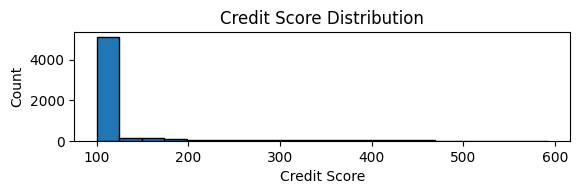

In [195]:
# 1. Credit Score Distribution
plt.subplot(3, 1, 1)
plt.hist(df['Credit Score'].dropna(), bins=20, edgecolor='black')
plt.title('Credit Score Distribution')
plt.xlabel('Credit Score')
plt.ylabel('Count')



Text(0, 0.5, 'Customers')

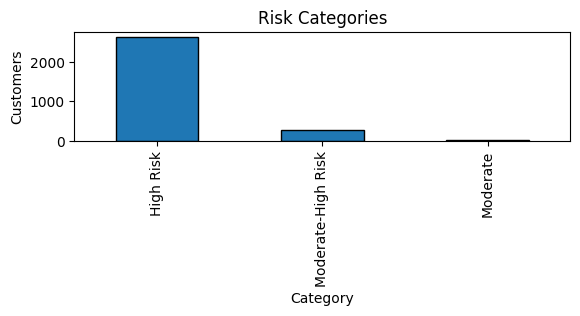

In [196]:
# 2. Risk Category Count
plt.subplot(3, 1, 2)
df['Risk Category'].value_counts().plot(kind='bar', edgecolor='black')
plt.title('Risk Categories')
plt.xlabel('Category')
plt.ylabel('Customers')



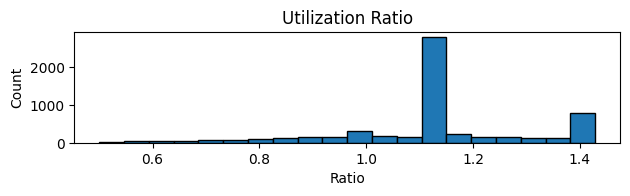

In [197]:
# 3. Utilization Ratio
plt.subplot(3, 1, 3)
plt.hist(df['Credit Utilization Ratio'].dropna(), bins=20, edgecolor='black')
plt.title('Utilization Ratio')
plt.xlabel('Ratio')
plt.ylabel('Count')

plt.tight_layout()
plt.show()

## **Excel Report with Color-coded Risk** ##

In [198]:
#pip install xlsxwriter

In [199]:
with pd.ExcelWriter("Risk_Report new.xlsx", engine='xlsxwriter') as writer:
    df.to_excel(writer, index=False, sheet_name='Risk Data')
    workbook  = writer.book
    worksheet = writer.sheets['Risk Data']

    # Format Credit Score with gradient
    format1 = workbook.add_format({'num_format': '0', 'bg_color': '#FFC7CE', 'font_color': '#9C0006'})
    worksheet.conditional_format('Q2:Q1000', {'type': '3_color_scale'})

    # Format Risk Category as colored text
    format_risk = {
        'High Risk': workbook.add_format({'bg_color': '#FF0000', 'bold': True}),
        'Low Risk': workbook.add_format({'bg_color': '#00FF00', 'bold': True}),
        'Moderate': workbook.add_format({'bg_color': '#FFFF00', 'bold': True})
    }

    for row in range(1, len(df)):
        val = df.loc[row, 'Risk Category']
        fmt = format_risk.get(str(val), None)
        if fmt:
            worksheet.write(row, df.columns.get_loc('Risk Category'), val, fmt)


## **Cluster Analysis (Customer Segmentation)** ##
Group similar customers together:
e.g., fast payers, risky overusers, reliable long-term

In [ ]:

features = df[['Credit Score', 'Credit Utilization Ratio', 'Average Delay Days', 'Payment Ratio']].fillna(0)

# Standardize
scaler = StandardScaler()
scaled = scaler.fit_transform(features)

# Apply clustering
kmeans = KMeans(n_clusters=4, random_state=42)
unique_particulars['Cluster'] = kmeans.fit_predict(scaled)

# Save new version
unique_particulars.to_csv("unique_particulars_clustered.csv", index=False)


c:\Users\gzar9\AppData\Local\Programs\Python\Python310\lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\gzar9\AppData\Local\Programs\Python\Python310\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "c:\Users\gzar9\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 503, in run
    with Popen(*popenargs, **kwargs) as process:
  File "c:\Users\gzar9\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 971, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\gzar9\AppData\Local\Programs\Python\Python310\lib\subp

In [201]:
df.columns

Index(['particular_id', 'Particulars', 'Normalized', 'gross total of sales',
       'Total credit', 'Total receipt count', 'sales value', 'Net sales',
       'Payment Ratio', 'Average Delay Days', 'Average Delay Months',
       'Delayed', 'Delayed Super', 'Credit Ratio', 'Sales Variability',
       'Receipt Variability', 'Norm Payment', 'Norm Delay',
       'Norm Sales Consistency', 'Norm Receipt Consistency', 'Delay Penalty',
       'Credit Penalty', 'Credit Score Raw', 'Credit Score', 'Risk Category',
       'Early Payment Ratio', 'Delayed > 90%', 'Credit', 'Inactivity Ratio',
       'First Transaction', 'Last Transaction', 'Estimated Credit Limit',
       'Credit Utilization Ratio', 'Utilization Risk'],
      dtype='object')

In [202]:
unique_particulars.columns

Index(['particular_id', 'Particulars', 'Normalized', 'gross total of sales',
       'Total credit', 'Total receipt count', 'sales value', 'Net sales',
       'Payment Ratio', 'Average Delay Days', 'Average Delay Months',
       'Delayed', 'Delayed Super', 'Credit Ratio', 'Sales Variability',
       'Receipt Variability', 'Norm Payment', 'Norm Delay',
       'Norm Sales Consistency', 'Norm Receipt Consistency', 'Delay Penalty',
       'Credit Penalty', 'Credit Score Raw', 'Credit Score', 'Risk Category',
       'Early Payment Ratio', 'Delayed > 90%', 'Credit', 'Inactivity Ratio',
       'First Transaction', 'Last Transaction', 'Estimated Credit Limit',
       'Credit Utilization Ratio', 'Utilization Risk', 'Cluster'],
      dtype='object')

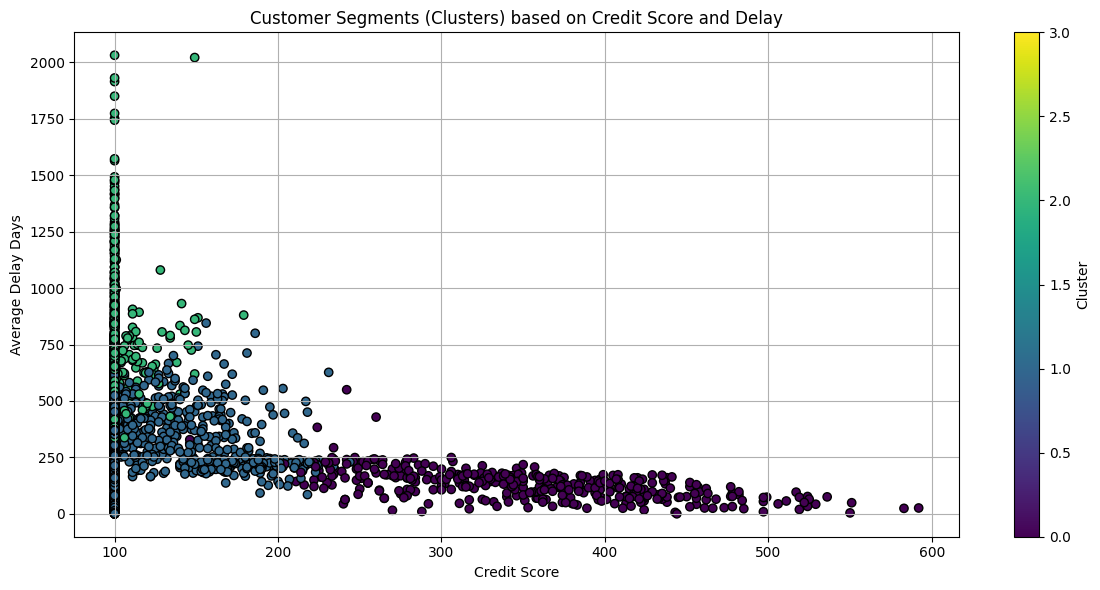

In [203]:
clustered_df = pd.read_csv("unique_particulars_clustered.csv", encoding='ISO-8859-1')
plt.figure(figsize=(12, 6))
scatter = plt.scatter(
    clustered_df['Credit Score'],
    clustered_df['Average Delay Days'],
    c=clustered_df['Cluster'],
    cmap='viridis',
    edgecolors='k'
)

plt.title('Customer Segments (Clusters) based on Credit Score and Delay')
plt.xlabel('Credit Score')
plt.ylabel('Average Delay Days')
plt.colorbar(scatter, label='Cluster')
plt.grid(True)
plt.tight_layout()
plt.show()

Chart Explanation:
X-axis: Credit Score

Y-axis: Average Delay Days

Colors: Different clusters (grouped behavior)

Interpretation:

Top-left: Low Score + High Delay → High Risk Cluster

Bottom-right: High Score + Low Delay → Reliable Customers

Other clusters fall in between with mixed behavior

## **MACHINE LEARNING** ##

In [ ]:



# Step 1: Read file into unique_particulars
unique_particulars = pd.read_csv("unique_particulars_clustered.csv", encoding='ISO-8859-1')

# Step 2: Ensure key columns are numeric
unique_particulars['Credit Score'] = pd.to_numeric(unique_particulars['Credit Score'], errors='coerce')
unique_particulars['Average Delay Days'] = pd.to_numeric(unique_particulars['Average Delay Days'], errors='coerce')

# Step 3: Will_Delay_Next (if score is low or delay > 30 days)
unique_particulars['Will_Delay_Next'] = (
    (unique_particulars['Average Delay Days'] > 30) | 
    (unique_particulars['Credit Score'] < 500)
).astype(int)

# Step 4: Add placeholder columns
unique_particulars['Delay_Prob'] = None
unique_particulars['Action Score'] = None

# Step 5: Score Trend
unique_particulars['Previous Score'] = unique_particulars['Credit Score'] - 50
unique_particulars['Score Trend'] = unique_particulars['Credit Score'] - unique_particulars['Previous Score']

# Step 6: Delay Frequency (normalized)
max_delay = unique_particulars['Average Delay Days'].max()
if pd.notna(max_delay) and max_delay != 0:
    unique_particulars['Delay Frequency'] = unique_particulars['Average Delay Days'] / max_delay
else:
    unique_particulars['Delay Frequency'] = 0

# Step 7: Recovery Time (how far from 900)
unique_particulars['Recovery Time'] = (900 - unique_particulars['Credit Score']) / 100

# Step 8: Save final version
unique_particulars.to_csv("unique_particulars_clustered.csv", index=False)


In [205]:
df.columns

Index(['particular_id', 'Particulars', 'Normalized', 'gross total of sales',
       'Total credit', 'Total receipt count', 'sales value', 'Net sales',
       'Payment Ratio', 'Average Delay Days', 'Average Delay Months',
       'Delayed', 'Delayed Super', 'Credit Ratio', 'Sales Variability',
       'Receipt Variability', 'Norm Payment', 'Norm Delay',
       'Norm Sales Consistency', 'Norm Receipt Consistency', 'Delay Penalty',
       'Credit Penalty', 'Credit Score Raw', 'Credit Score', 'Risk Category',
       'Early Payment Ratio', 'Delayed > 90%', 'Credit', 'Inactivity Ratio',
       'First Transaction', 'Last Transaction', 'Estimated Credit Limit',
       'Credit Utilization Ratio', 'Utilization Risk'],
      dtype='object')

In [206]:
df.shape

(5856, 34)

In [207]:
unique_particulars.shape

(5856, 42)

In [208]:
unique_particulars.columns

Index(['particular_id', 'Particulars', 'Normalized', 'gross total of sales',
       'Total credit', 'Total receipt count', 'sales value', 'Net sales',
       'Payment Ratio', 'Average Delay Days', 'Average Delay Months',
       'Delayed', 'Delayed Super', 'Credit Ratio', 'Sales Variability',
       'Receipt Variability', 'Norm Payment', 'Norm Delay',
       'Norm Sales Consistency', 'Norm Receipt Consistency', 'Delay Penalty',
       'Credit Penalty', 'Credit Score Raw', 'Credit Score', 'Risk Category',
       'Early Payment Ratio', 'Delayed > 90%', 'Credit', 'Inactivity Ratio',
       'First Transaction', 'Last Transaction', 'Estimated Credit Limit',
       'Credit Utilization Ratio', 'Utilization Risk', 'Cluster',
       'Will_Delay_Next', 'Delay_Prob', 'Action Score', 'Previous Score',
       'Score Trend', 'Delay Frequency', 'Recovery Time'],
      dtype='object')

In [210]:
print(unique_particulars.columns.tolist())


['particular_id', 'Particulars', 'Normalized', 'gross total of sales', 'Total credit', 'Total receipt count', 'sales value', 'Net sales', 'Payment Ratio', 'Average Delay Days', 'Average Delay Months', 'Delayed', 'Delayed Super', 'Credit Ratio', 'Sales Variability', 'Receipt Variability', 'Norm Payment', 'Norm Delay', 'Norm Sales Consistency', 'Norm Receipt Consistency', 'Delay Penalty', 'Credit Penalty', 'Credit Score Raw', 'Credit Score', 'Risk Category', 'Early Payment Ratio', 'Delayed > 90%', 'Credit', 'Inactivity Ratio', 'First Transaction', 'Last Transaction', 'Estimated Credit Limit', 'Credit Utilization Ratio', 'Utilization Risk', 'Cluster', 'Will_Delay_Next', 'Delay_Prob', 'Action Score', 'Previous Score', 'Score Trend', 'Delay Frequency', 'Recovery Time']


In [211]:
unique_particulars.shape

(5856, 42)

In [212]:
# Drop the columns: 'Previous Score' and 'Score Trend'
unique_particulars.drop(columns=['Previous Score', 'Score Trend'], inplace=True, errors='ignore')
# Save to your working file
unique_particulars.to_csv("unique_particulars_clustered.csv", index=False)

In [213]:
unique_particulars.shape

(5856, 40)

In [214]:
advance_pay = valid_delays[valid_delays['delay_days'] < 0]
advance_ratio = (
    advance_pay.groupby('particular_id')['Credit'].sum() /
    valid_delays.groupby('particular_id')['Credit'].sum()
).reset_index(name='Advance Payment Ratio')


In [215]:
# Select features for model training
features = [
    'Credit Score',
    'Average Delay Days',
    'Credit Utilization Ratio',
    'Delay Frequency',
    'Recovery Time'
]

# Ensure features are numeric
X = unique_particulars[features].apply(pd.to_numeric, errors='coerce')
y = unique_particulars['Will_Delay_Next']

# Drop rows with missing values in features or target
X = X.dropna()
y = y[X.index]

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train model
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

# Predict probabilities on full data
unique_particulars['Delay_Prob'] = model.predict_proba(X)[:, 1]

# Create Action Score (scaled)
unique_particulars['Action Score'] = (unique_particulars['Delay_Prob'] * 100).round(2)

# Save updated data back to original file
unique_particulars.to_csv("unique_particulars_clustered.csv", index=False)


In [216]:
unique_particulars.shape

(5856, 40)

In [217]:
import joblib

# Save trained model
joblib.dump(model, r"D:\Insightrix Project\Nova Agri Project\combined datawork\delay_prob_risk_model.pkl")


['D:\\Insightrix Project\\Nova Agri Project\\combined datawork\\delay_prob_risk_model.pkl']

## **Delay Index Calculation using minmax scaler** ##

In [ ]:


# Define a copy to avoid modifying the original
df = unique_particulars.copy()

# Columns used to compute Delay Index
delay_index_features = [
    'Average Delay Days',
    'Delayed > 90%',
    'Delay Frequency',
    'Will_Delay_Next',
    'Delay_Prob',
    'Credit Score'
]

# Ensure all columns exist and convert to numeric
for col in delay_index_features:
    if col not in df.columns:
        df[col] = 0
    df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0)

# Normalize all columns except Credit Score (which will be inverted)
scaler = MinMaxScaler()
df_scaled = scaler.fit_transform(df[delay_index_features[:-1]])  # all except Credit Score
df_scaled = pd.DataFrame(df_scaled, columns=delay_index_features[:-1])

# Invert and normalize Credit Score (higher score = lower risk)
df_scaled['Credit Score'] = 1 - scaler.fit_transform(df[['Credit Score']])

# Delay Index formula (weights can be adjusted)
df['Delay Index'] = (
    0.30 * df_scaled['Average Delay Days'] +
    0.15 * df_scaled['Delayed > 90%'] +
    0.20 * df_scaled['Delay Frequency'] +
    0.10 * df_scaled['Will_Delay_Next'] +
    0.20 * df_scaled['Delay_Prob'] +
    0.05 * df_scaled['Credit Score']
).round(4) * 100  # scale to 0–100

# Step 1: Add Delay Index to original
unique_particulars['Delay Index'] = df['Delay Index']

# Step 2: Save updated dataset
unique_particulars.to_csv("unique_particulars_clustered.csv", index=False)


In [219]:
unique_particulars.shape

(5856, 41)

In [220]:
unique_particulars.columns

Index(['particular_id', 'Particulars', 'Normalized', 'gross total of sales',
       'Total credit', 'Total receipt count', 'sales value', 'Net sales',
       'Payment Ratio', 'Average Delay Days', 'Average Delay Months',
       'Delayed', 'Delayed Super', 'Credit Ratio', 'Sales Variability',
       'Receipt Variability', 'Norm Payment', 'Norm Delay',
       'Norm Sales Consistency', 'Norm Receipt Consistency', 'Delay Penalty',
       'Credit Penalty', 'Credit Score Raw', 'Credit Score', 'Risk Category',
       'Early Payment Ratio', 'Delayed > 90%', 'Credit', 'Inactivity Ratio',
       'First Transaction', 'Last Transaction', 'Estimated Credit Limit',
       'Credit Utilization Ratio', 'Utilization Risk', 'Cluster',
       'Will_Delay_Next', 'Delay_Prob', 'Action Score', 'Delay Frequency',
       'Recovery Time', 'Delay Index'],
      dtype='object')

In [221]:
df.shape

(5856, 41)

In [222]:
df.columns

Index(['particular_id', 'Particulars', 'Normalized', 'gross total of sales',
       'Total credit', 'Total receipt count', 'sales value', 'Net sales',
       'Payment Ratio', 'Average Delay Days', 'Average Delay Months',
       'Delayed', 'Delayed Super', 'Credit Ratio', 'Sales Variability',
       'Receipt Variability', 'Norm Payment', 'Norm Delay',
       'Norm Sales Consistency', 'Norm Receipt Consistency', 'Delay Penalty',
       'Credit Penalty', 'Credit Score Raw', 'Credit Score', 'Risk Category',
       'Early Payment Ratio', 'Delayed > 90%', 'Credit', 'Inactivity Ratio',
       'First Transaction', 'Last Transaction', 'Estimated Credit Limit',
       'Credit Utilization Ratio', 'Utilization Risk', 'Cluster',
       'Will_Delay_Next', 'Delay_Prob', 'Action Score', 'Delay Frequency',
       'Recovery Time', 'Delay Index'],
      dtype='object')

In [223]:
# Delay Index Flag Buckets
unique_particulars['Delay_Risk_Flag'] = pd.cut(
    unique_particulars['Delay Index'],
    bins=[0, 40, 70, 100],
    labels=['Low Risk', 'Medium Risk', 'High Risk']
)


In [224]:
# Save the updated DataFrame with Delay_Risk_Flag added
unique_particulars.to_csv("unique_particulars_clustered.csv", index=False)


## **As delay probability important to find future prediction so retraining the model with XGboost** ##

In [225]:
unique_values_count = unique_particulars['Delay_Prob'].value_counts()
print(unique_values_count)

Delay_Prob
1.000000    4968
1.000000      54
1.000000      21
1.000000      14
1.000000      13
            ... 
1.000000       1
0.999986       1
1.000000       1
1.000000       1
0.999992       1
Name: count, Length: 696, dtype: int64


In [ ]:



# Prepare the data again (using the same features)
features = [
    'Credit Score',
    'Average Delay Days',
    'Credit Utilization Ratio',
    'Delay Frequency',
    'Recovery Time'
]

# Ensure features are numeric and drop missing
X = unique_particulars[features].apply(pd.to_numeric, errors='coerce')
y = unique_particulars['Will_Delay_Next']
X = X.dropna()
y = y[X.index]

# Train XGBoost model
model = XGBClassifier(use_label_encoder=False, eval_metric='logloss')
model.fit(X, y)

# Overwrite Delay_Prob and Action Score
unique_particulars.loc[X.index, 'Delay_Prob'] = model.predict_proba(X)[:, 1]
unique_particulars.loc[X.index, 'Action Score'] = (unique_particulars.loc[X.index, 'Delay_Prob'] * 100).round(2)

# Save the updated dataset
unique_particulars.to_csv("unique_particulars_clustered.csv", index=False)



c:\Users\gzar9\AppData\Local\Programs\Python\Python310\lib\site-packages\xgboost\training.py:183: UserWarning: [08:08:10] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


## **Creating cibil score for each particular** ##

In [227]:
# Rebalanced CIBIL Score formula

unique_particulars['CIBIL_SCORE'] = (
    900
    - (unique_particulars['Delay_Prob'].clip(0, 1) * 200)
    - (unique_particulars['Delay Frequency'].clip(0, 1) * 50)
    - (unique_particulars['Recovery Time'].clip(0, 10) * 20)
    - (unique_particulars['Delayed > 90%'].clip(0, 1) * 50)
    - (unique_particulars['Credit Utilization Ratio'].clip(0, 1) * 50)
    + (unique_particulars['Early Payment Ratio'].clip(0, 1) * 100)
    - (unique_particulars['Inactivity Ratio'].clip(0, 1) * 30)
).round().clip(300, 900)
# Save the updated dataset with CIBIL_SCORE
unique_particulars.to_csv("unique_particulars_clustered.csv", index=False)

In [228]:
unique_particulars[['particular_id', 'CIBIL_SCORE']].head()


,particular_id,CIBIL_SCORE
0,1,423.0
1,2,417.0
2,3,413.0
3,4,419.0
4,5,422.0


## **creating CIBIL BAND** ##

In [229]:
unique_particulars['CIBIL_Band'] = pd.cut(
    unique_particulars['CIBIL_SCORE'],
    bins=[300, 600, 750, 900],
    labels=['High Risk', 'Medium Risk', 'Low Risk']
)


In [230]:
# Save the updated dataset with CIBIL_SCORE
unique_particulars.to_csv("unique_particulars_clustered.csv", index=False)
unique_particulars[['particular_id', 'CIBIL_SCORE','CIBIL_Band']].head()


,particular_id,CIBIL_SCORE,CIBIL_Band
0,1,423.0,High Risk
1,2,417.0,High Risk
2,3,413.0,High Risk
3,4,419.0,High Risk
4,5,422.0,High Risk


In [231]:
model = XGBClassifier()
model.fit(X_train, y_train)

# ✅ Export to file
joblib.dump(model, r"xgboost_model.pkl")

['xgboost_model.pkl']

In [232]:
unique_particulars.columns

Index(['particular_id', 'Particulars', 'Normalized', 'gross total of sales',
       'Total credit', 'Total receipt count', 'sales value', 'Net sales',
       'Payment Ratio', 'Average Delay Days', 'Average Delay Months',
       'Delayed', 'Delayed Super', 'Credit Ratio', 'Sales Variability',
       'Receipt Variability', 'Norm Payment', 'Norm Delay',
       'Norm Sales Consistency', 'Norm Receipt Consistency', 'Delay Penalty',
       'Credit Penalty', 'Credit Score Raw', 'Credit Score', 'Risk Category',
       'Early Payment Ratio', 'Delayed > 90%', 'Credit', 'Inactivity Ratio',
       'First Transaction', 'Last Transaction', 'Estimated Credit Limit',
       'Credit Utilization Ratio', 'Utilization Risk', 'Cluster',
       'Will_Delay_Next', 'Delay_Prob', 'Action Score', 'Delay Frequency',
       'Recovery Time', 'Delay Index', 'Delay_Risk_Flag', 'CIBIL_SCORE',
       'CIBIL_Band'],
      dtype='object')

In [234]:
df = pd.read_csv("unique_particulars_clustered.csv")

features_to_use = [
    'gross total of sales', 'Total credit', 'Total receipt count', 'sales value', 'Net sales',
    'Payment Ratio', 'Average Delay Days', 'Credit Ratio', 'Sales Variability',
    'Receipt Variability', 'Norm Payment', 'Norm Delay', 'Norm Sales Consistency',
    'Norm Receipt Consistency', 'Early Payment Ratio', 'Delayed > 90%', 'Inactivity Ratio',
    'Estimated Credit Limit', 'Credit Utilization Ratio'
]

target_score = 'Credit Score'
target_delay = 'Will_Delay_Next'

df = df.dropna(subset=features_to_use + [target_score, target_delay])

X = df[features_to_use]
y_score = df[target_score]
y_delay = df[target_delay]


In [235]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


In [237]:


sm = SMOTE(random_state=42, k_neighbors=2)  # instead of default 5
X_res, y_delay_res = sm.fit_resample(X_scaled, y_delay)


In [ ]:


ros = RandomOverSampler(random_state=42)
X_res, y_delay_res = ros.fit_resample(X_scaled, y_delay)


In [239]:
# Credit Score Regression
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(X_scaled, y_score, test_size=0.2, random_state=42)

# Delay Classification (SMOTE balanced)
X_train_d, X_test_d, y_train_d, y_test_d = train_test_split(X_res, y_delay_res, test_size=0.2, random_state=42)


In [240]:
reg = XGBRegressor(n_estimators=200, learning_rate=0.05, max_depth=5, random_state=42)
reg.fit(X_train_s, y_train_s)
y_pred_score = reg.predict(X_test_s)


In [241]:
clf = XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=4, scale_pos_weight=3, random_state=42)
clf.fit(X_train_d, y_train_d)
y_pred_delay = clf.predict(X_test_d)


In [242]:
print("🎯 Credit Score Prediction")
print("MAE:", mean_absolute_error(y_test_s, y_pred_score))
print("R2 Score:", r2_score(y_test_s, y_pred_score))

print("\n⏳ Delay Classification Report")
print(classification_report(y_test_d, y_pred_delay))
print("Confusion Matrix:\n", confusion_matrix(y_test_d, y_pred_delay))


🎯 Credit Score Prediction
MAE: 2.6749495092919253
R2 Score: 0.9791198977135995

⏳ Delay Classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1159
           1       1.00      1.00      1.00      1182

    accuracy                           1.00      2341
   macro avg       1.00      1.00      1.00      2341
weighted avg       1.00      1.00      1.00      2341

Confusion Matrix:
 [[1159    0]
 [   0 1182]]


In [243]:
df['XGB_Credit_Score'] = reg.predict(scaler.transform(df[features_to_use]))
df['XGB_Will_Delay_Next'] = clf.predict(scaler.transform(df[features_to_use]))


In [244]:
df.to_csv("unique_particulars_clustered_XGBoostNew.csv", index=False)
print("✅ Results saved to unique_particulars_clustered_XGBoostNew.csv")


✅ Results saved to unique_particulars_clustered_XGBoostNew.csv


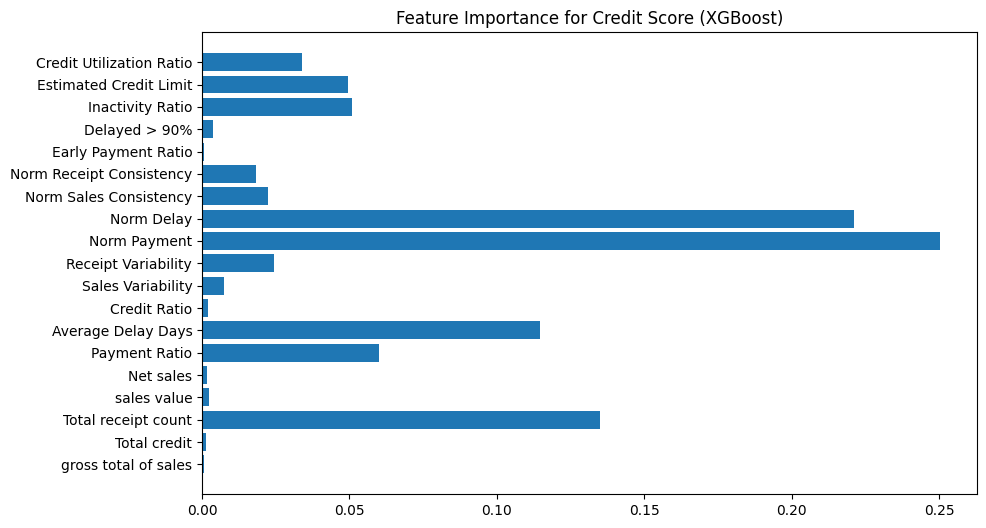

In [245]:
plt.figure(figsize=(10, 6))
plt.barh(features_to_use, reg.feature_importances_)
plt.title("Feature Importance for Credit Score (XGBoost)")
plt.show()


## **As i used to train XGBoost model for predicting will they delay next or not also this process is predicting using manual mathematical expression and i verified that there is only four customers that will not delay also with Model training i got same output as they delay or not** ##

## **Risk Category using XGboost** ##

In [247]:
df.columns

Index(['particular_id', 'Particulars', 'Normalized', 'gross total of sales',
       'Total credit', 'Total receipt count', 'sales value', 'Net sales',
       'Payment Ratio', 'Average Delay Days', 'Average Delay Months',
       'Delayed', 'Delayed Super', 'Credit Ratio', 'Sales Variability',
       'Receipt Variability', 'Norm Payment', 'Norm Delay',
       'Norm Sales Consistency', 'Norm Receipt Consistency', 'Delay Penalty',
       'Credit Penalty', 'Credit Score Raw', 'Credit Score', 'Risk Category',
       'Early Payment Ratio', 'Delayed > 90%', 'Credit', 'Inactivity Ratio',
       'First Transaction', 'Last Transaction', 'Estimated Credit Limit',
       'Credit Utilization Ratio', 'Utilization Risk', 'Cluster',
       'Will_Delay_Next', 'Delay_Prob', 'Action Score', 'Delay Frequency',
       'Recovery Time', 'Delay Index', 'Delay_Risk_Flag', 'CIBIL_SCORE',
       'CIBIL_Band', 'XGB_Credit_Score', 'XGB_Will_Delay_Next'],
      dtype='object')

In [249]:
unique_particulars.columns

Index(['particular_id', 'Particulars', 'Normalized', 'gross total of sales',
       'Total credit', 'Total receipt count', 'sales value', 'Net sales',
       'Payment Ratio', 'Average Delay Days', 'Average Delay Months',
       'Delayed', 'Delayed Super', 'Credit Ratio', 'Sales Variability',
       'Receipt Variability', 'Norm Payment', 'Norm Delay',
       'Norm Sales Consistency', 'Norm Receipt Consistency', 'Delay Penalty',
       'Credit Penalty', 'Credit Score Raw', 'Credit Score', 'Risk Category',
       'Early Payment Ratio', 'Delayed > 90%', 'Credit', 'Inactivity Ratio',
       'First Transaction', 'Last Transaction', 'Estimated Credit Limit',
       'Credit Utilization Ratio', 'Utilization Risk', 'Cluster',
       'Will_Delay_Next', 'Delay_Prob', 'Action Score', 'Delay Frequency',
       'Recovery Time', 'Delay Index', 'Delay_Risk_Flag', 'CIBIL_SCORE',
       'CIBIL_Band'],
      dtype='object')

In [ ]:

# Encode target
le = LabelEncoder()
y_encoded = le.fit_transform(df['Risk Category'])

# Features
X = df[[
    'Average Delay Days', 'Payment Ratio', 
    'Sales Variability', 'Receipt Variability'
]].fillna(0)

# Scale
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Split
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_encoded, test_size=0.2, random_state=42)


In [252]:
mlp = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation='relu',
    solver='adam',
    max_iter=300,
    random_state=42
)
mlp.fit(X_train, y_train)

# Predict
y_pred = mlp.predict(X_test)


In [254]:
# Fix risk_category column
df['Risk Category'] = df['Risk Category'].astype(str).fillna('Unknown')

# Encode properly
le = LabelEncoder()
y_encoded = le.fit_transform(df['Risk Category'])


In [256]:
df = df[df['Risk Category'].notna()]  # Remove rows with missing category


In [257]:
print(df['Risk Category'].value_counts())


Risk Category
nan                   2964
High Risk             2621
Moderate-High Risk     256
Moderate                15
Name: count, dtype: int64


In [258]:
# Clean again
df['Risk Category'] = df['Risk Category'].astype(str).fillna('Unknown')
le = LabelEncoder()
y_encoded = le.fit_transform(df['Risk Category'])


In [ ]:

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=le.classes_))


Confusion Matrix:
[[496   0   6  21]
 [  0   0   1   1]
 [  6   1  34   0]
 [ 12   0   0 594]]

Classification Report:
                    precision    recall  f1-score   support

         High Risk       0.96      0.95      0.96       523
          Moderate       0.00      0.00      0.00         2
Moderate-High Risk       0.83      0.83      0.83        41
               nan       0.96      0.98      0.97       606

          accuracy                           0.96      1172
         macro avg       0.69      0.69      0.69      1172
      weighted avg       0.96      0.96      0.96      1172



In [ ]:

# Split data
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_encoded, test_size=0.2, random_state=42)

# Train model
mlp = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation='relu',
    solver='adam',
    max_iter=300,
    random_state=42
)
mlp.fit(X_train, y_train)


MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=300, random_state=42)

In [260]:
# Predict
y_pred = mlp.predict(X_test)

# Evaluate
target_names = [str(cls) for cls in le.classes_]
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=target_names))


Confusion Matrix:
 [[496   0   6  21]
 [  0   0   1   1]
 [  6   1  34   0]
 [ 12   0   0 594]]

Classification Report:
                     precision    recall  f1-score   support

         High Risk       0.96      0.95      0.96       523
          Moderate       0.00      0.00      0.00         2
Moderate-High Risk       0.83      0.83      0.83        41
               nan       0.96      0.98      0.97       606

          accuracy                           0.96      1172
         macro avg       0.69      0.69      0.69      1172
      weighted avg       0.96      0.96      0.96      1172



In [261]:
df['DL_Risk_Category_Encoded'] = mlp.predict(X_scaled)
df['DL_Risk_Category'] = le.inverse_transform(df['DL_Risk_Category_Encoded'])


In [264]:
# Step 1: Clean up
df = df[df['Risk Category'].notna()]  # Remove NaNs
df['Risk Category'] = df['Risk Category'].replace({
    'Moderate': 'Moderate-High Risk',
    'nan': 'Unknown'  # Just in case string 'nan' exists
}).astype(str)


In [265]:
features = [
    'Average Delay Days', 'Payment Ratio', 
    'Sales Variability', 'Receipt Variability'
]

X = df[features].fillna(0)  # Replace any numeric NaNs
y = df['Risk Category']

# Encode class labels
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded)


In [266]:
mlp = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation='relu',
    solver='adam',
    max_iter=500,
    random_state=42
)
mlp.fit(X_train, y_train)


MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=500, random_state=42)

In [267]:
y_pred = mlp.predict(X_test)

print("✅ Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\n📊 Classification Report:")
print(classification_report(y_test, y_pred, target_names=[str(c) for c in le.classes_]))


✅ Confusion Matrix:
[[508   6  11]
 [  5  48   1]
 [ 16   6 571]]

📊 Classification Report:
                    precision    recall  f1-score   support

         High Risk       0.96      0.97      0.96       525
Moderate-High Risk       0.80      0.89      0.84        54
           Unknown       0.98      0.96      0.97       593

          accuracy                           0.96      1172
         macro avg       0.91      0.94      0.93      1172
      weighted avg       0.96      0.96      0.96      1172



In [269]:
df.to_csv("unique_particulars_clustered_XGBoostNew2.csv", index=False)
print("✅ Results saved to unique_particulars_clustered_XGBoostNew2.csv")


✅ Results saved to unique_particulars_clustered_XGBoostNew2.csv


In [270]:
df.columns

Index(['particular_id', 'Particulars', 'Normalized', 'gross total of sales',
       'Total credit', 'Total receipt count', 'sales value', 'Net sales',
       'Payment Ratio', 'Average Delay Days', 'Average Delay Months',
       'Delayed', 'Delayed Super', 'Credit Ratio', 'Sales Variability',
       'Receipt Variability', 'Norm Payment', 'Norm Delay',
       'Norm Sales Consistency', 'Norm Receipt Consistency', 'Delay Penalty',
       'Credit Penalty', 'Credit Score Raw', 'Credit Score', 'Risk Category',
       'Early Payment Ratio', 'Delayed > 90%', 'Credit', 'Inactivity Ratio',
       'First Transaction', 'Last Transaction', 'Estimated Credit Limit',
       'Credit Utilization Ratio', 'Utilization Risk', 'Cluster',
       'Will_Delay_Next', 'Delay_Prob', 'Action Score', 'Delay Frequency',
       'Recovery Time', 'Delay Index', 'Delay_Risk_Flag', 'CIBIL_SCORE',
       'CIBIL_Band', 'XGB_Credit_Score', 'XGB_Will_Delay_Next',
       'DL_Risk_Category_Encoded', 'DL_Risk_Category'],
      

In [271]:
features = [
    'Payment Ratio', 'Credit Ratio', 'Average Delay Days', 'Average Delay Months',
    'Delay Frequency', 'Recovery Time', 'Inactivity Ratio',
    'Sales Variability', 'Receipt Variability', 'Credit Utilization Ratio',
    'Credit Score', 'Action Score', 'CIBIL_SCORE'
]

df_anom = df[features].dropna()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_anom)


In [272]:
input_dim = X_scaled.shape[1]

input_layer = Input(shape=(input_dim,))
encoded = Dense(64, activation='relu')(input_layer)
encoded = Dense(32, activation='relu')(encoded)
encoded = Dense(16, activation='relu')(encoded)

decoded = Dense(32, activation='relu')(encoded)
decoded = Dense(64, activation='relu')(decoded)
output_layer = Dense(input_dim, activation='linear')(decoded)

autoencoder = Model(inputs=input_layer, outputs=output_layer)
autoencoder.compile(optimizer='adam', loss='mse')
autoencoder.summary()



Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 13)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 13)             │           845 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,005 (27.36 KB)

 Trainable params: 7,005 (27.36 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

X_train, X_test = train_test_split(X_scaled, test_size=0.2, random_state=42)

history = autoencoder.fit(
    X_train, X_train,
    epochs=100,
    batch_size=32,
    shuffle=True,
    validation_data=(X_test, X_test),
    verbose=1
)


Epoch 1/100
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.6919 - val_loss: 0.3468
Epoch 2/100
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2111 - val_loss: 0.2566
Epoch 3/100
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.1251 - val_loss: 0.0984
Epoch 4/100
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0601 - val_loss: 0.0292
Epoch 5/100
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0285 - val_loss: 0.0237
Epoch 6/100
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0506 - val_loss: 0.0217
Epoch 7/100
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0333 - val_loss: 0.0248
Epoch 8/100
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0272 - val_loss: 0.0143
Epoch 9/100
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0156 - val_loss: 0.0122
Epoch 10/100
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0126 - val_loss: 0.0119
Epoch 11/100
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0209 - val_loss: 0.0090
Epoch 12/100
147/147 ━━━━━━━━━━━━━━━━━━━━

In [274]:
X_pred = autoencoder.predict(X_scaled)
reconstruction_error = np.mean(np.power(X_scaled - X_pred, 2), axis=1)

df_anom['Reconstruction Error'] = reconstruction_error


183/183 ━━━━━━━━━━━━━━━━━━━━ 0s 595us/step


In [275]:
threshold = np.percentile(reconstruction_error, 95)  # Top 5% as anomaly
df_anom['Is_Anomaly'] = (reconstruction_error > threshold).astype(int)


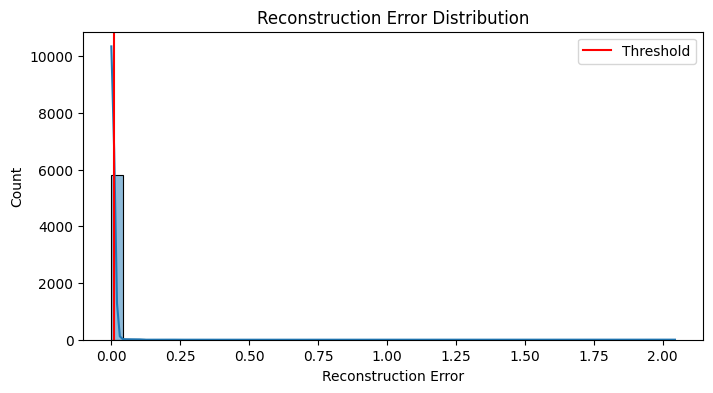

In [276]:
plt.figure(figsize=(8,4))
sns.histplot(df_anom['Reconstruction Error'], bins=50, kde=True)
plt.axvline(threshold, color='red', label='Threshold')
plt.title("Reconstruction Error Distribution")
plt.legend()
plt.show()


In [277]:
anomalies = df_anom[df_anom['Is_Anomaly'] == 1]
print("🚨 Anomalies Found:", anomalies.shape[0])
anomalies.head()


🚨 Anomalies Found: 293


,Payment Ratio,Credit Ratio,Average Delay Days,Average Delay Months,Delay Frequency,Recovery Time,Inactivity Ratio,Sales Variability,Receipt Variability,Credit Utilization Ratio,Credit Score,Action Score,CIBIL_SCORE,Reconstruction Error,Is_Anomaly
12,-1.799950,2.2501,849.04,28.30,0.417835,8.00,0.890411,1.6261,1.02150,1.4286,100.0,100.00,399.0,0.010233,1
33,1.760442,0.6377,1284.79,42.83,0.632279,8.00,0.876712,1.3338,1.69040,1.4286,100.0,100.00,402.0,0.008478,1
60,21.890700,0.9563,91.59,3.05,0.045074,4.22,0.863014,0.4838,0.35360,0.6595,478.0,99.77,542.0,0.009409,1
75,-1.215067,5.6497,2032.00,67.73,1.000000,8.00,0.986301,0.8148,0.65125,1.1296,100.0,100.00,366.0,0.009920,1
91,-1.556377,2.7973,156.50,5.22,0.077018,8.00,0.972603,0.5757,0.00000,0.7021,100.0,100.00,440.0,0.009845,1


In [278]:
# Step 1: Copy back the results safely
df.loc[df_anom.index, 'Reconstruction Error'] = df_anom['Reconstruction Error']
df.loc[df_anom.index, 'Is_Anomaly'] = df_anom['Is_Anomaly']


In [279]:
df.to_csv("unique_particulars_clustered_XGBoostNew2.csv", index=False)
print("✅ File saved as with anomaly.csv")


✅ File saved as with anomaly.csv


In [ ]:

xgb_score_model = XGBRegressor(n_estimators=200, learning_rate=0.05, max_depth=5, random_state=42)
xgb_score_model.fit(X_train_s, y_train_s)


XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=200,
             n_jobs=None, num_parallel_tree=None, ...)

In [284]:
xgb_score_model = reg


## **Future Customer Input and their Prediction** ##

In [291]:
df.columns

Index(['particular_id', 'Particulars', 'Normalized', 'gross total of sales',
       'Total credit', 'Total receipt count', 'sales value', 'Net sales',
       'Payment Ratio', 'Average Delay Days', 'Average Delay Months',
       'Delayed', 'Delayed Super', 'Credit Ratio', 'Sales Variability',
       'Receipt Variability', 'Norm Payment', 'Norm Delay',
       'Norm Sales Consistency', 'Norm Receipt Consistency', 'Delay Penalty',
       'Credit Penalty', 'Credit Score Raw', 'Credit Score', 'Risk Category',
       'Early Payment Ratio', 'Delayed > 90%', 'Credit', 'Inactivity Ratio',
       'First Transaction', 'Last Transaction', 'Estimated Credit Limit',
       'Credit Utilization Ratio', 'Utilization Risk', 'Cluster',
       'Will_Delay_Next', 'Delay_Prob', 'Action Score', 'Delay Frequency',
       'Recovery Time', 'Delay Index', 'Delay_Risk_Flag', 'CIBIL_SCORE',
       'CIBIL_Band', 'XGB_Credit_Score', 'XGB_Will_Delay_Next',
       'DL_Risk_Category_Encoded', 'DL_Risk_Category', 'Recons

In [ ]:

# Create a unified prediction function
def predict_new_customer(data_dict, scaler, xgb_score_model, xgb_delay_model,
                         mlp_risk_model, le_risk, autoencoder, threshold, feature_list):
    """
    Predicts credit score, delay status, risk category, and anomaly for a new customer.
    
    Parameters:
    - data_dict: dict of new customer features
    - scaler: fitted StandardScaler
    - xgb_score_model: trained XGBRegressor
    - xgb_delay_model: trained XGBClassifier
    - mlp_risk_model: trained MLPClassifier
    - le_risk: fitted LabelEncoder for risk categories
    - autoencoder: trained autoencoder model
    - threshold: float, anomaly detection threshold
    - feature_list: list of features used in training
    
    Returns:
    - dict of predictions
    """
    # Convert to DataFrame and ensure correct feature order
    input_df = pd.DataFrame([data_dict])
    input_df = input_df[feature_list]  # reorder to match training

    # Scale the input
    X_scaled = scaler.transform(input_df)

    # Predict credit score
    predicted_credit_score = xgb_score_model.predict(X_scaled)[0]

    # Predict delay
    delay_prediction = xgb_delay_model.predict(X_scaled)[0]
    delay_prob = xgb_delay_model.predict_proba(X_scaled)[0][1]

    # Predict risk category
    risk_encoded = mlp_risk_model.predict(X_scaled)[0]
    risk_category = le_risk.inverse_transform([risk_encoded])[0]

    # Anomaly detection
    reconstructed = autoencoder.predict(X_scaled)
    reconstruction_error = np.mean(np.power(X_scaled - reconstructed, 2))
    is_anomaly = int(reconstruction_error > threshold)

    # Final results
    return {
        "Predicted Credit Score": round(predicted_credit_score, 2),
        "Will Delay Next": "Yes" if delay_prediction else "No",
        "Delay Probability": round(delay_prob, 2),
        "Risk Category": risk_category,
        "Reconstruction Error": round(reconstruction_error, 6),
        "Is Anomaly": "Yes" if is_anomaly else "No"
    }


## **Exporting all model** ##

In [ ]:


# Step 1: Assign models to proper names
xgb_score_model = reg               # XGBRegressor for Credit Score
xgb_delay_model = clf              # XGBClassifier for Will Delay
mlp_risk_model = mlp               # MLPClassifier for Risk Category
le_risk = le                       # LabelEncoder for risk

# Step 2: Save Scaler
joblib.dump(scaler, "scaler.pkl")

# Step 3: Save Models
joblib.dump(xgb_score_model, "xgb_score_model.pkl")
joblib.dump(xgb_delay_model, "xgb_delay_model.pkl")
joblib.dump(mlp_risk_model, "mlp_risk_model.pkl")

# Step 4: Save LabelEncoder
joblib.dump(le_risk, "le_risk_encoder.pkl")

# Step 5: Save Features List
joblib.dump(features_to_use, "features_to_use.pkl")

# Step 6: Save Autoencoder (Deep Learning Model)
autoencoder.save("autoencoder_model.h5")

# Step 7: Save Anomaly Threshold
joblib.dump(threshold, "anomaly_threshold.pkl")



['anomaly_threshold.pkl']

## **predict new customer** ##

In [ ]:


autoencoder = load_model("autoencoder_model.h5", compile=False)
autoencoder.compile(optimizer='adam', loss=MeanSquaredError())


In [302]:
autoencoder.save("autoencoder_model.keras")


In [303]:
autoencoder = load_model("autoencoder_model.keras")


c:\Users\gzar9\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\saving\saving_lib.py:757: UserWarning: Skipping variable loading for optimizer 'adam', because it has 26 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [ ]:


# Step 1: Load the autoencoder with compile=False to bypass loss issue
autoencoder = load_model("autoencoder_model.h5", compile=False)

# Step 2: Manually compile with MSE
autoencoder.compile(optimizer='adam', loss=MeanSquaredError())


In [312]:
# Load all ML/DL components
scaler = joblib.load("scaler.pkl")
xgb_score_model = joblib.load("xgb_score_model.pkl")
xgb_delay_model = joblib.load("xgb_delay_model.pkl")
mlp_risk_model = joblib.load("mlp_risk_model.pkl")
le_risk = joblib.load("le_risk_encoder.pkl")
features_to_use = joblib.load("features_to_use.pkl")
threshold = joblib.load("anomaly_threshold.pkl")
autoencoder = load_model("autoencoder_model.keras")
